# Notebook 04: K-Means Customer Segmentation

**Project:** Customer Segmentation and Retention Analysis Using Machine Learning and Statistical Modelling  
**Dataset scope:** Year 1 — December 2009 to December 2010 (UK-based online retail)  
**Notebook series position:** 04 of N  
**Depends on:** Notebooks 01, 02, 03  

---

## 1. Project Objective and Research Questions

This notebook implements a rigorous, reproducible K-Means clustering workflow to segment the Year 1 Online Retail II customer base into behaviourally meaningful groups, built on validated RFM features from Notebook 02 and informed by the inter-purchase interval analysis in Notebook 03.

### Research questions
1. How many meaningfully distinct customer segments exist in the Year 1 dataset?
2. What defines each segment in terms of recency, purchase frequency, and spending volume?
3. Which segments represent the highest commercial value and warrant retention attention?
4. How does the empirical P90 inactivity threshold (~102 days) distribute across segments?

### Methodological constraints (documented upfront)
- **Primary features:** RFM only. AOV = Monetary/Frequency (mathematically redundant).
- **Median_InterPurchase_Days:** Excluded — 1,421/4,314 customers (32.9%) have a single purchase. Zero imputation is methodologically incorrect (implies immediate repurchase).
- **Cancellation_Rate:** Used descriptively in profiling only.
- **Inactivity flag:** Applied post-clustering as a descriptor, never as a model input.
- **Scope:** Year 1 only (Dec 2009–Dec 2010). No Year 2 data loaded.
- **NOT performed here:** Survival analysis, Cox models, log-rank tests, or future churn prediction.


---
## 2. Imports and Reproducible Configuration


In [1]:
# Standard library
import json
import warnings
from pathlib import Path
from collections import Counter

# Data manipulation
import numpy as np
import pandas as pd

# Visualisation
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

# Machine learning
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    calinski_harabasz_score,
    davies_bouldin_score,
    silhouette_score,
    adjusted_rand_score,
)
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

plt.rcParams.update({
    'figure.dpi': 120,
    'figure.facecolor': 'white',
    'axes.facecolor': '#f8f9fa',
    'axes.grid': True,
    'grid.alpha': 0.4,
    'font.family': 'DejaVu Sans',
    'axes.titlesize': 13,
    'axes.labelsize': 11,
})

pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', '{:.4f}'.format)

import sklearn
print(f'numpy {np.__version__} | pandas {pd.__version__} | scikit-learn {sklearn.__version__}')
print(f'matplotlib {matplotlib.__version__} | seaborn {sns.__version__}')
print(f'Random seed: {RANDOM_STATE}')


numpy 2.3.5 | pandas 2.3.3 | scikit-learn 1.9.1
matplotlib 3.10.0 | seaborn 0.13.2
Random seed: 42


---
## 3. Input Loading and Validation


In [2]:
def resolve_path(candidates):
    for c in candidates:
        p = Path(c)
        if p.exists():
            return p
    raise FileNotFoundError(f'None of the candidates exist: {candidates}')

CUSTOMER_FEATURES_PATH = resolve_path([
    '../data/processed/customer_features.csv',
    'data/processed/customer_features.csv',
    'main_project/data/processed/customer_features.csv',
])
CLEANED_DATA_PATH = resolve_path([
    '../data/processed/online_retail_cleaned_data.csv',
    'data/processed/online_retail_cleaned_data.csv',
    'main_project/data/processed/online_retail_cleaned_data.csv',
])
THRESHOLD_PATH = resolve_path([
    '../data/processed/inactivity_threshold.json',
    'data/processed/inactivity_threshold.json',
    'main_project/data/processed/inactivity_threshold.json',
])
DIST_RESULTS_PATH = resolve_path([
    '../data/processed/interpurchase_distribution_results.csv',
    'data/processed/interpurchase_distribution_results.csv',
    'main_project/data/processed/interpurchase_distribution_results.csv',
])
PROCESSED_DIR = CUSTOMER_FEATURES_PATH.parent

for label, path in [
    ('customer_features.csv', CUSTOMER_FEATURES_PATH),
    ('online_retail_cleaned_data.csv', CLEANED_DATA_PATH),
    ('inactivity_threshold.json', THRESHOLD_PATH),
    ('interpurchase_distribution_results.csv', DIST_RESULTS_PATH),
]:
    print(f'  {label}: {path}')
print(f'Output directory: {PROCESSED_DIR}')


  customer_features.csv: ..\data\processed\customer_features.csv
  online_retail_cleaned_data.csv: ..\data\processed\online_retail_cleaned_data.csv
  inactivity_threshold.json: ..\data\processed\inactivity_threshold.json
  interpurchase_distribution_results.csv: ..\data\processed\interpurchase_distribution_results.csv
Output directory: ..\data\processed


In [3]:
# 3.1 Load and inspect customer_features.csv
cf_raw = pd.read_csv(CUSTOMER_FEATURES_PATH)

print('=' * 55)
print('customer_features.csv')
print('=' * 55)
print(f'Shape: {cf_raw.shape[0]:,} rows x {cf_raw.shape[1]} columns')
print(f'Columns: {list(cf_raw.columns)}')
mv = cf_raw.isnull().sum()
print('\nMissing values (columns with >0):')
print(mv[mv > 0].to_string())
print('\nDescriptive statistics:')
cf_raw.describe()


customer_features.csv
Shape: 4,314 rows x 15 columns
Columns: ['Customer ID', 'Recency', 'Frequency', 'Monetary_Gross', 'Monetary_Net', 'AOV', 'Median_InterPurchase_Days', 'Cancellation_Count', 'Cancellation_Rate', 'Monetary', 'Recency_Transformed', 'Frequency_Transformed', 'Monetary_Transformed', 'AOV_Transformed', 'Median_InterPurchase_Transformed']

Missing values (columns with >0):
Median_InterPurchase_Days           1421
Median_InterPurchase_Transformed    1421

Descriptive statistics:


,Customer ID,Recency,Frequency,Monetary_Gross,Monetary_Net,AOV,Median_InterPurchase_Days,Cancellation_Count,Cancellation_Rate,Monetary,Recency_Transformed,Frequency_Transformed,Monetary_Transformed,AOV_Transformed,Median_InterPurchase_Transformed
count,4314.0000,4314.0000,4314.0000,4314.0000,4314.0000,4314.0000,2893.0000,4314.0000,4314.0000,4314.0000,4314.0000,4314.0000,4314.0000,4314.0000,2893.0000
mean,15348.8804,91.2691,4.4541,2039.4608,1941.9256,376.1989,65.7926,0.9961,0.1221,2039.4608,0.0000,1.3708,0.0000,0.0000,-0.0000
std,1700.9301,96.9435,8.1687,8909.7978,8568.0675,492.3100,64.0982,2.4576,0.1760,8909.7978,1.0001,0.6906,1.0001,1.0001,1.0002
min,12346.0000,1.0000,1.0000,0.0000,-10953.5000,0.0000,0.0007,0.0000,0.0000,0.0000,-2.0708,0.6931,-5.8659,-6.5399,-2.2830
25%,13883.2500,18.0000,1.0000,307.1050,296.0775,179.4000,21.0708,0.0000,0.0000,307.1050,-0.7679,0.6931,-0.6674,-0.5908,-0.6650
50%,15348.5000,53.0000,2.0000,700.4050,670.1600,284.8550,44.9007,0.0000,0.0000,700.4050,0.0058,1.0986,-0.0151,0.0162,-0.0355
75%,16833.7500,136.0000,5.0000,1713.2975,1663.5725,421.4500,88.8312,1.0000,0.2500,1713.2975,0.8071,1.7918,0.6694,0.5426,0.6644
max,18287.0000,374.0000,205.0000,349164.3500,341776.7300,11880.8400,361.8417,65.0000,0.8333,349164.3500,1.8116,5.3279,4.2676,5.4931,2.6064


In [4]:
# 3.2 Validate customer count
EXPECTED_CUSTOMERS = 4314
n_feature_rows = len(cf_raw)
n_unique_ids = cf_raw['Customer ID'].nunique()
n_dup = n_feature_rows - n_unique_ids

print(f'Total rows      : {n_feature_rows:,}')
print(f'Unique IDs      : {n_unique_ids:,}')
print(f'Duplicate IDs   : {n_dup}')
assert n_dup == 0, 'FAIL: Duplicate Customer IDs!'
print('[PASS] No duplicate Customer IDs.')

if n_feature_rows == EXPECTED_CUSTOMERS:
    print(f'[PASS] Count matches TEST01_Report: {EXPECTED_CUSTOMERS:,}')
else:
    print(f'[DISCREPANCY] Expected {EXPECTED_CUSTOMERS:,}; found {n_feature_rows:,}.')


Total rows      : 4,314
Unique IDs      : 4,314
Duplicate IDs   : 0
[PASS] No duplicate Customer IDs.
[PASS] Count matches TEST01_Report: 4,314


In [5]:
# 3.3 Load cleaned transactions for scope/sanity checks
print('Loading cleaned transaction data...')
txn = pd.read_csv(
    CLEANED_DATA_PATH,
    usecols=['Invoice', 'InvoiceDate', 'Customer ID', 'Price', 'Quantity', 'StockCode'],
    parse_dates=['InvoiceDate'],
)

print(f'Rows          : {len(txn):,}')
print(f'Unique cust.  : {txn["Customer ID"].nunique():,}')
print(f'Date range    : {txn["InvoiceDate"].min()} to {txn["InvoiceDate"].max()}')

years_present = sorted(txn['InvoiceDate'].dt.year.unique())
print(f'Years present : {years_present}')
assert set(years_present) <= {2009, 2010}, f'FAIL: unexpected years {years_present}'
print('[PASS] All transactions within Year 1 (2009-2010).')

missing_cust = txn['Customer ID'].isnull().sum()
assert missing_cust == 0, f'FAIL: {missing_cust} missing Customer IDs'
print('[PASS] No missing Customer IDs.')

is_cancel = txn['Invoice'].astype(str).str.startswith('C')
print(f'\nCancellation rows : {is_cancel.sum():,}')
print(f'Purchase rows     : {(~is_cancel).sum():,}')
purchase_txn = txn[~is_cancel].copy()
print(f'Unique customers with 1+ purchase: {purchase_txn["Customer ID"].nunique():,}')


Loading cleaned transaction data...


Rows          : 410,763
Unique cust.  : 4,383
Date range    : 2009-12-01 07:45:00 to 2010-12-09 20:01:00
Years present : [np.int32(2009), np.int32(2010)]
[PASS] All transactions within Year 1 (2009-2010).
[PASS] No missing Customer IDs.

Cancellation rows : 9,816
Purchase rows     : 400,947
Unique customers with 1+ purchase: 4,314


In [6]:
# 3.4 Test account investigation: Customer IDs 14103 and 14827
TEST_ACCOUNTS = [14103, 14827]
test_txn = txn[txn['Customer ID'].isin(TEST_ACCOUNTS)]

print('Transaction records for test accounts:')
if len(test_txn) > 0:
    print(test_txn[['Invoice','StockCode','Quantity','Price','InvoiceDate','Customer ID']].to_string(index=False))
else:
    print('  Not found in cleaned data.')

test_features = cf_raw[cf_raw['Customer ID'].isin(TEST_ACCOUNTS)]
print('\nFeature file rows for test accounts:')
print(test_features[['Customer ID','Recency','Frequency','Monetary_Gross','Monetary_Net','Cancellation_Rate']].to_string(index=False))

all_zero_price = (test_txn['Price'] == 0.0).all() if len(test_txn) > 0 else False
all_test001 = test_txn['StockCode'].str.upper().eq('TEST001').all() if len(test_txn) > 0 else False
print(f'\nAll transactions Price=0.00    : {all_zero_price}')
print(f'All transactions StockCode TEST001: {all_test001}')

EXCLUDE_TEST_ACCOUNTS = bool(all_zero_price and all_test001)
if EXCLUDE_TEST_ACCOUNTS:
    print('\n[DECISION] Test-account status CONFIRMED. Will EXCLUDE customers 14103 & 14827.')
    print('  Rationale: Only TEST001 StockCode at GBP 0.00 = system testing, not genuine behaviour.')
else:
    print('\n[NOTE] Test-account status not confirmed -- retaining.')


Transaction records for test accounts:
Invoice StockCode  Quantity  Price         InvoiceDate  Customer ID
 497819   TEST001         5 0.0000 2010-02-12 14:58:00        14103
 497843   TEST001         5 0.0000 2010-02-12 15:47:00        14827

Feature file rows for test accounts:
 Customer ID  Recency  Frequency  Monetary_Gross  Monetary_Net  Cancellation_Rate
       14103      301          1          0.0000        0.0000             0.0000
       14827      301          1          0.0000        0.0000             0.0000

All transactions Price=0.00    : True
All transactions StockCode TEST001: True

[DECISION] Test-account status CONFIRMED. Will EXCLUDE customers 14103 & 14827.
  Rationale: Only TEST001 StockCode at GBP 0.00 = system testing, not genuine behaviour.


In [7]:
# 3.5 Load and validate inactivity threshold from Notebook 03
with open(THRESHOLD_PATH, 'r') as fh:
    threshold_meta = json.load(fh)

INACTIVITY_THRESHOLD_DAYS = threshold_meta['selected_threshold_days']
N_GAP_OBS = threshold_meta['n_gap_observations']
N_CUSTOMERS_WITH_GAPS = threshold_meta['n_customers_with_gaps']

print(f'Dataset scope       : {threshold_meta["dataset_scope"]}')
print(f'Best distribution   : {threshold_meta["best_distribution"]}')
print(f'Gamma shape         : {threshold_meta["gamma_shape"]:.6f}')
print(f'Gamma scale         : {threshold_meta["gamma_scale"]:.6f}')
print(f'n gap observations  : {N_GAP_OBS:,}')
print(f'n customers w/ gaps : {N_CUSTOMERS_WITH_GAPS:,}')
print(f'Selected threshold  : {INACTIVITY_THRESHOLD_DAYS:.1f} days (empirical P90)')
print(f'Empirical P90       : {threshold_meta["threshold_range_days"]["empirical_p90"]} days')
print(f'Gamma P90           : {threshold_meta["threshold_range_days"]["gamma_p90"]} days')

nb02_repeat = cf_raw['Median_InterPurchase_Days'].notna().sum()
print(f'\nCross-check NB02 repeat customers: {nb02_repeat:,}')
print(f'NB03 n_customers_with_gaps      : {N_CUSTOMERS_WITH_GAPS:,}')
if nb02_repeat == N_CUSTOMERS_WITH_GAPS:
    print('[PASS] Both notebooks agree on repeat-purchase customer count.')
else:
    print(f'[DISCREPANCY] NB02={nb02_repeat} vs NB03={N_CUSTOMERS_WITH_GAPS}')


Dataset scope       : Year 2009-2010 (Dec 2009 to Dec 2010)
Best distribution   : Gamma
Gamma shape         : 0.377824
Gamma scale         : 103.365887
n gap observations  : 14,831
n customers w/ gaps : 2,893
Selected threshold  : 101.9 days (empirical P90)
Empirical P90       : 101.9 days
Gamma P90           : 111.4 days

Cross-check NB02 repeat customers: 2,893
NB03 n_customers_with_gaps      : 2,893
[PASS] Both notebooks agree on repeat-purchase customer count.


In [8]:
# 3.6 Distribution results and NB02 vs NB03 reconciliation
dist_df = pd.read_csv(DIST_RESULTS_PATH)
print('Interpurchase distribution results (Notebook 03):')
print(dist_df[['distribution','n_observations','aic','bic','ks_statistic','p90_model_days']].to_string(index=False))

print('\n--- NB02 vs NB03 count reconciliation ---')
print(f'NB02: stores ONE Median_InterPurchase_Days per customer  -> {nb02_repeat:,} non-null values')
print(f'NB03: uses ALL individual pairwise gaps                  -> {N_GAP_OBS:,} observations')
print(f'  Avg gaps per repeat customer: {N_GAP_OBS/N_CUSTOMERS_WITH_GAPS:.2f}')
print('[VERDICT] Not a discrepancy -- different units: one summary per customer vs all gap events.')


Interpurchase distribution results (Notebook 03):
distribution  n_observations         aic         bic  ks_statistic  p90_model_days
 Exponential           14831 138373.6557 138381.2602        0.1381         89.9300
     Weibull           14831 126370.2970 126385.5060        0.1247        129.8500
       Gamma           14831 123759.7246 123774.9336        0.1237        111.4000
  Log-Normal           14831 134678.4467 134693.6556        0.2326        504.1700

--- NB02 vs NB03 count reconciliation ---
NB02: stores ONE Median_InterPurchase_Days per customer  -> 2,893 non-null values
NB03: uses ALL individual pairwise gaps                  -> 14,831 observations
  Avg gaps per repeat customer: 5.13
[VERDICT] Not a discrepancy -- different units: one summary per customer vs all gap events.


---
## 4. Customer Feature Preparation

We exclude confirmed test accounts and select the RFM features for clustering.

**Why RFM only?**
- **AOV = Monetary_Gross / Frequency** — mathematically redundant; both components are already in the model.
- **Median_InterPurchase_Days** — missing for 1,421 single-purchase customers (32.9%). Zero imputation implies instantaneous repurchase — methodologically incorrect.
- **Cancellation_Rate** — used descriptively in cluster profiling.


In [9]:
# 4.1 Apply test account exclusion
df = cf_raw.copy()

if EXCLUDE_TEST_ACCOUNTS:
    before = len(df)
    df = df[~df['Customer ID'].isin(TEST_ACCOUNTS)].reset_index(drop=True)
    after = len(df)
    print(f'Excluded {before - after} test account(s): {TEST_ACCOUNTS}')
    print(f'  Before: {before:,} | After: {after:,}')
else:
    print('Test accounts retained (status unconfirmed).')

N_CLUSTERING_CUSTOMERS = len(df)
print(f'\nCustomers available for clustering: {N_CLUSTERING_CUSTOMERS:,}')


Excluded 2 test account(s): [14103, 14827]
  Before: 4,314 | After: 4,312

Customers available for clustering: 4,312


In [10]:
# 4.2 Select RFM features and validate
RFM_COLS = ['Recency', 'Frequency', 'Monetary_Gross']
rfm = df[RFM_COLS].copy()

assert rfm.isnull().sum().sum() == 0, 'FAIL: Missing values in RFM'
print('[PASS] No missing values in RFM features.')

assert np.isinf(rfm.values).sum() == 0, 'FAIL: Infinite values in RFM'
print('[PASS] No infinite values.')

assert rfm['Recency'].min() >= 1, 'FAIL: Recency < 1'
print(f'[PASS] Recency: min={rfm["Recency"].min()}, max={rfm["Recency"].max()}')

assert rfm['Frequency'].min() >= 1, 'FAIL: Frequency < 1'
print(f'[PASS] Frequency: min={rfm["Frequency"].min()}, max={rfm["Frequency"].max()}')

n_neg_mon = (rfm['Monetary_Gross'] < 0).sum()
n_zero_mon = (rfm['Monetary_Gross'] == 0).sum()
assert n_neg_mon == 0, f'FAIL: {n_neg_mon} negative Monetary_Gross values'
print(f'[PASS] Monetary_Gross: no negatives. Zero count: {n_zero_mon}')
if n_zero_mon > 0:
    zero_ids = df.loc[rfm['Monetary_Gross'] == 0, 'Customer ID'].tolist()
    print(f'  Zero Monetary_Gross IDs: {zero_ids} (expect empty if test accounts excluded)')

print('\nRFM descriptive statistics:')
rfm.describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99])


[PASS] No missing values in RFM features.
[PASS] No infinite values.
[PASS] Recency: min=1, max=374
[PASS] Frequency: min=1, max=205
[PASS] Monetary_Gross: no negatives. Zero count: 0

RFM descriptive statistics:


,Recency,Frequency,Monetary_Gross
count,4312.0000,4312.0000,4312.0000
mean,91.1718,4.4557,2040.4067
std,96.8606,8.1702,8911.7560
min,1.0000,1.0000,2.9500
10%,8.0000,1.0000,153.1320
25%,18.0000,1.0000,307.1875
50%,53.0000,2.0000,701.6150
75%,136.0000,5.0000,1714.9325
90%,254.9000,9.0000,3776.7910
95%,304.0000,13.0000,6191.0975


In [11]:
# 4.3 Reference date and Recency sanity check
REFERENCE_DATE = pd.Timestamp('2010-12-10 20:01:00')

sample_ids = df['Customer ID'].sample(5, random_state=RANDOM_STATE).tolist()
purch_small = purchase_txn[purchase_txn['Customer ID'].isin(sample_ids)]
last_purch = purch_small.groupby('Customer ID')['InvoiceDate'].max()
recomp_rec = (REFERENCE_DATE - last_purch).dt.days

print(f'Reference date: {REFERENCE_DATE}')
print('Recency sanity check (5 random customers):')
all_ok = True
for cid in sample_ids:
    stored = df.loc[df['Customer ID'] == cid, 'Recency'].values[0]
    recomp = recomp_rec.get(cid, None)
    ok = 'PASS' if stored == recomp else 'FAIL'
    if ok == 'FAIL': all_ok = False
    print(f'  Customer {int(cid):5d}: stored={stored}, recomputed={recomp} [{ok}]')
if all_ok:
    print('[PASS] All Recency values match recomputed values.')


Reference date: 2010-12-10 20:01:00
Recency sanity check (5 random customers):
  Customer 17576: stored=1, recomputed=1 [PASS]
  Customer 16886: stored=92, recomputed=92 [PASS]
  Customer 15518: stored=15, recomputed=15 [PASS]
  Customer 13656: stored=135, recomputed=135 [PASS]
  Customer 15620: stored=45, recomputed=45 [PASS]
[PASS] All Recency values match recomputed values.


---
## 5. Exploratory Feature Analysis


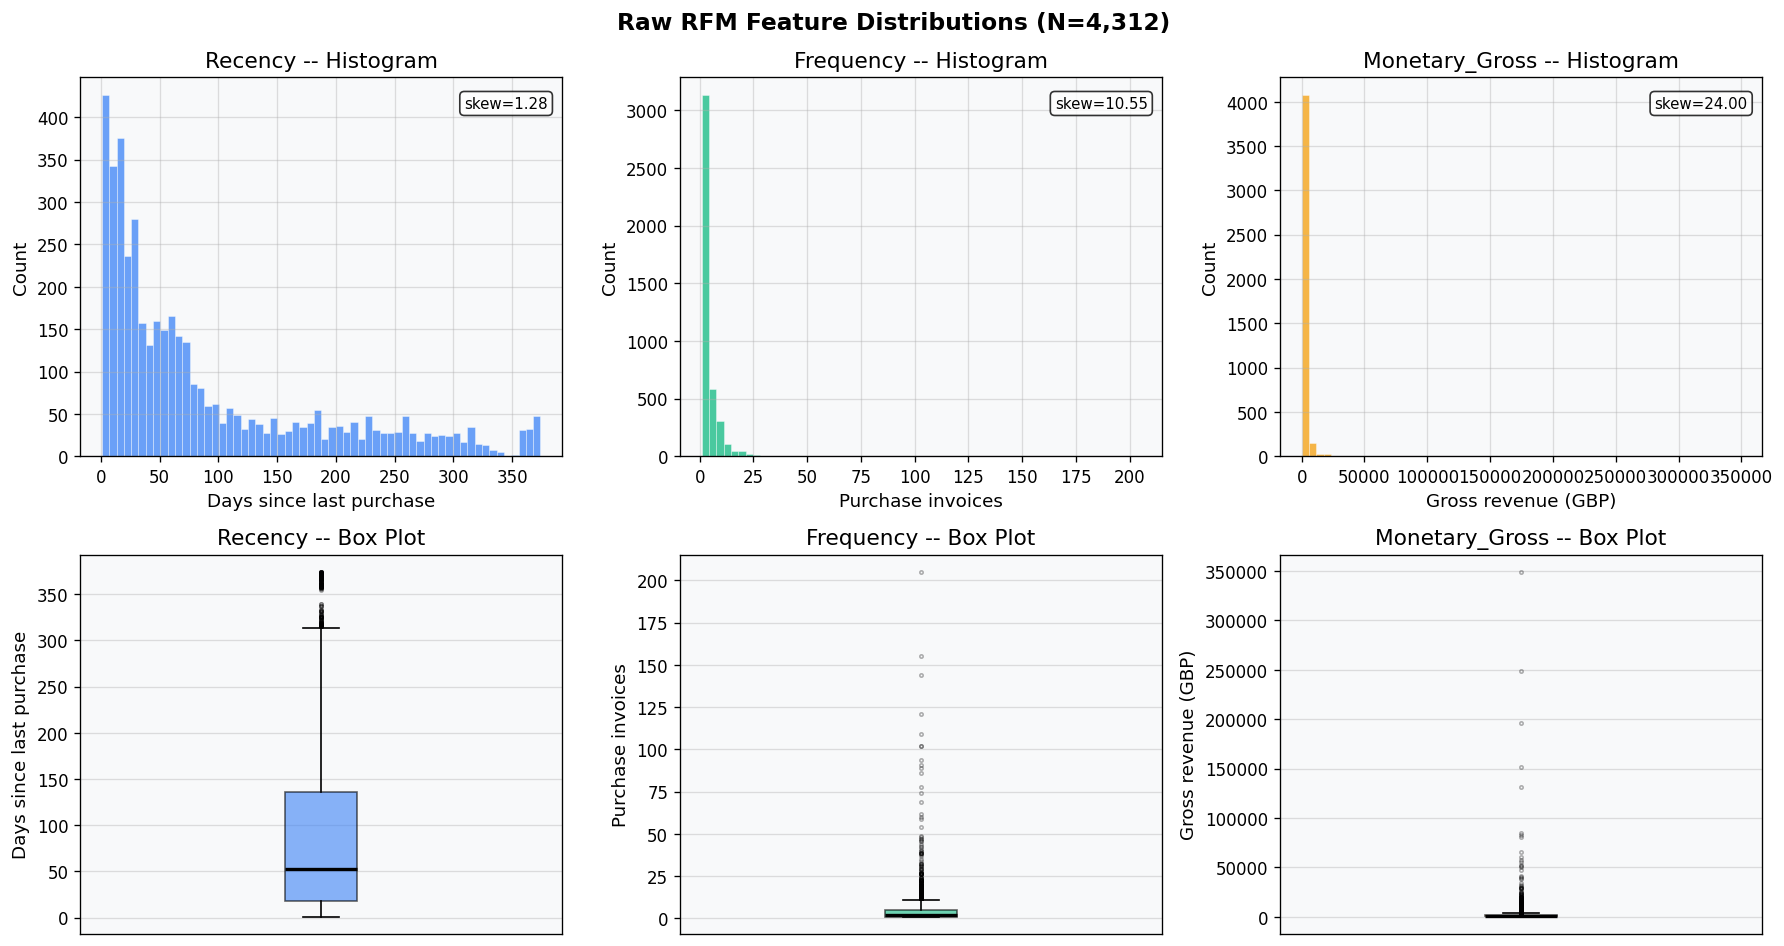

Recency             : skewness = 1.283
Frequency           : skewness = 10.547
Monetary_Gross      : skewness = 24.000


In [12]:
# 5.1 Raw RFM distributions
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
fig.suptitle(f'Raw RFM Feature Distributions (N={N_CLUSTERING_CUSTOMERS:,})', fontsize=14, fontweight='bold')

feat_info = [
    ('Recency', 'Days since last purchase', '#3B82F6'),
    ('Frequency', 'Purchase invoices', '#10B981'),
    ('Monetary_Gross', 'Gross revenue (GBP)', '#F59E0B'),
]

for ci, (col, xlabel, color) in enumerate(feat_info):
    ax_h = axes[0, ci]
    ax_h.hist(rfm[col], bins=60, color=color, alpha=0.75, edgecolor='white', linewidth=0.3)
    ax_h.set_title(f'{col} -- Histogram')
    ax_h.set_xlabel(xlabel)
    ax_h.set_ylabel('Count')
    ax_h.text(0.97, 0.95, f'skew={rfm[col].skew():.2f}', transform=ax_h.transAxes,
              ha='right', va='top', fontsize=9, bbox=dict(boxstyle='round,pad=0.3', fc='white', alpha=0.8))
    ax_b = axes[1, ci]
    ax_b.boxplot(rfm[col], vert=True, patch_artist=True,
                 boxprops=dict(facecolor=color, alpha=0.6),
                 medianprops=dict(color='black', linewidth=2),
                 flierprops=dict(marker='o', markersize=2, alpha=0.3))
    ax_b.set_title(f'{col} -- Box Plot')
    ax_b.set_ylabel(xlabel)
    ax_b.set_xticks([])

plt.tight_layout()
plt.show()

for col in RFM_COLS:
    print(f'{col:20s}: skewness = {rfm[col].skew():.3f}')


In [13]:
# 5.2 Single-purchase customer analysis
n_single = (df['Frequency'] == 1).sum()
n_repeat = (df['Frequency'] >= 2).sum()
pct_single = 100 * n_single / N_CLUSTERING_CUSTOMERS

print(f'Single-purchase (Freq=1) : {n_single:,} ({pct_single:.1f}%)')
print(f'Repeat-purchase (Freq>=2): {n_repeat:,} ({100-pct_single:.1f}%)')
print(f'Customers w/ valid gaps  : {df["Median_InterPurchase_Days"].notna().sum():,}')
print()
print('Decision: Median_InterPurchase_Days EXCLUDED from primary clustering inputs.')
print('  32.9% of customers have a single purchase; interval is undefined (NaN), not zero.')
print('  Imputing 0 would falsely imply immediate repurchase. NaN retention is correct.')
print('  Inter-purchase data will be used descriptively within cluster profiles.')


Single-purchase (Freq=1) : 1,419 (32.9%)
Repeat-purchase (Freq>=2): 2,893 (67.1%)
Customers w/ valid gaps  : 2,893

Decision: Median_InterPurchase_Days EXCLUDED from primary clustering inputs.
  32.9% of customers have a single purchase; interval is undefined (NaN), not zero.
  Imputing 0 would falsely imply immediate repurchase. NaN retention is correct.
  Inter-purchase data will be used descriptively within cluster profiles.


---
## 6. Transformation and Scaling

### Why transform?
K-Means uses squared Euclidean distances. Strongly skewed distributions with extreme outliers dominate distance calculations. Features also have different units (days, count, pounds), requiring standardisation.

| Feature | Raw Skewness | Transformation | Rationale |
|---|---|---|---|
| Recency | ~+1.3 | `log1p` | Non-negative; moderate right skew |
| Frequency | ~+10.5 | `log1p` | Non-negative; extreme right skew; Freq >= 1 |
| Monetary_Gross | ~+24 | `log1p` | Non-negative; very extreme right skew |

`log1p(x) = log(1+x)` is safe for all non-negative x (including zero). After log1p, features are standardised with **`StandardScaler`** (zero mean, unit variance).


In [14]:
# 6.1 Apply log1p transformation
for col in RFM_COLS:
    n_neg = (rfm[col] < 0).sum()
    if n_neg > 0:
        raise ValueError(f'{col} has {n_neg} negative values -- log1p invalid!')
print('[PASS] All RFM features non-negative -- log1p valid.')

rfm_log = rfm.copy()
rfm_log['log1p_Recency']   = np.log1p(rfm['Recency'])
rfm_log['log1p_Frequency'] = np.log1p(rfm['Frequency'])
rfm_log['log1p_Monetary']  = np.log1p(rfm['Monetary_Gross'])
LOG_COLS = ['log1p_Recency', 'log1p_Frequency', 'log1p_Monetary']

print('\nPost-transformation skewness:')
for orig, lc in zip(RFM_COLS, LOG_COLS):
    print(f'  {orig:20s}: {rfm[orig].skew():+.3f}  -->  {lc}: {rfm_log[lc].skew():+.3f}')


[PASS] All RFM features non-negative -- log1p valid.

Post-transformation skewness:
  Recency             : +1.283  -->  log1p_Recency: -0.425
  Frequency           : +10.547  -->  log1p_Frequency: +1.182
  Monetary_Gross      : +24.000  -->  log1p_Monetary: +0.266


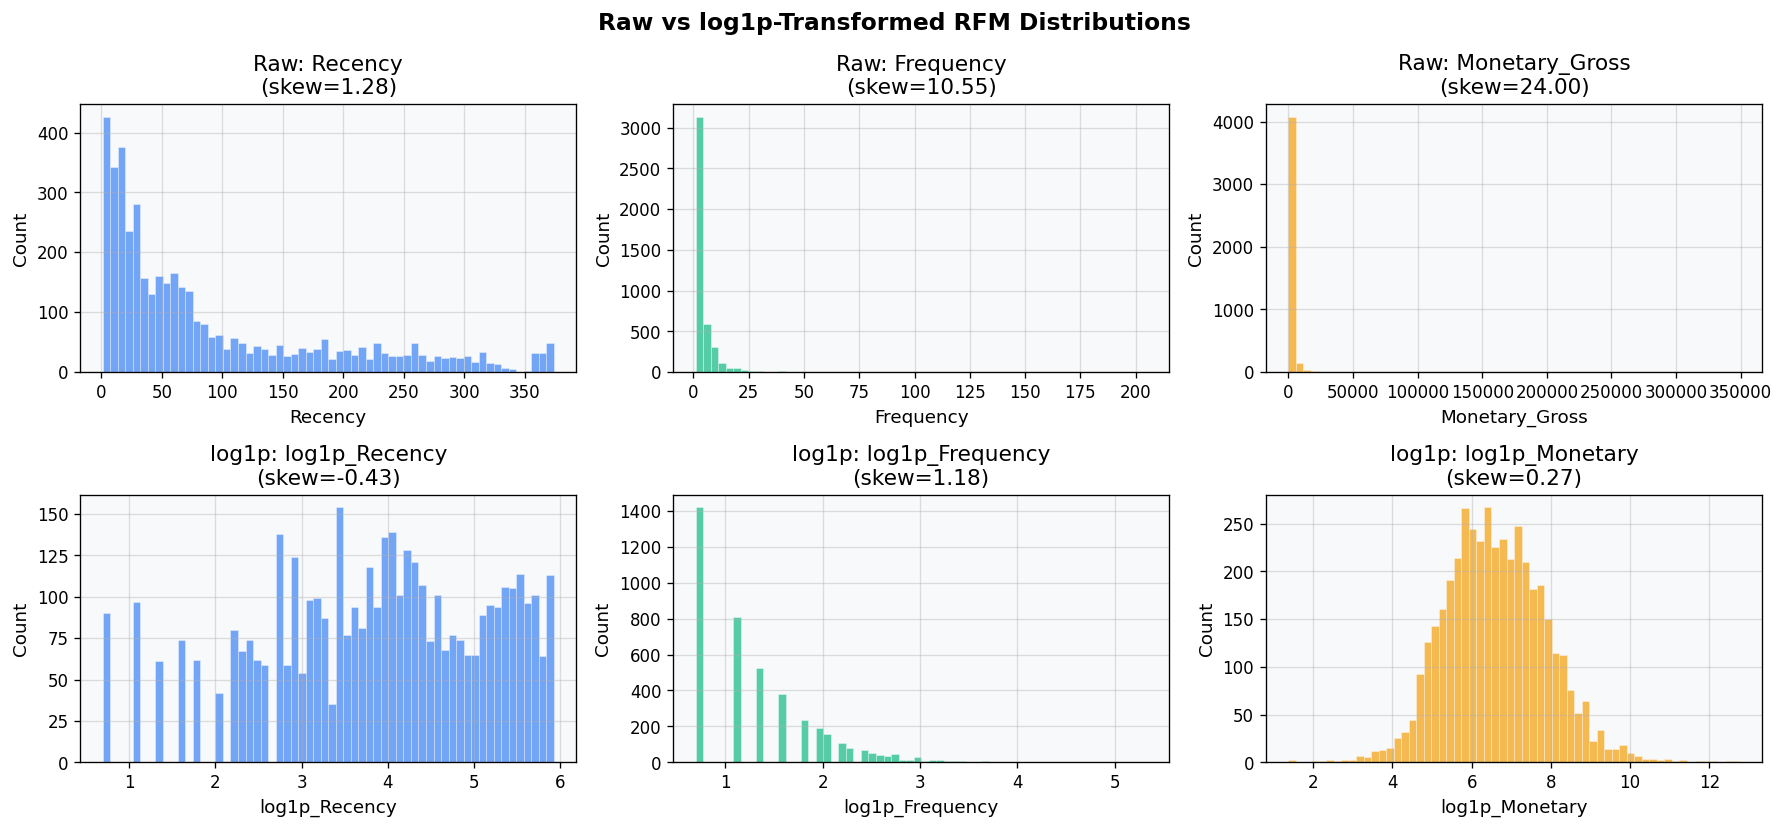

In [15]:
# 6.2 Raw vs log1p distribution comparison
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
fig.suptitle('Raw vs log1p-Transformed RFM Distributions', fontsize=14, fontweight='bold')

for ci, (orig, lc, color) in enumerate(zip(RFM_COLS, LOG_COLS, ['#3B82F6','#10B981','#F59E0B'])):
    axes[0, ci].hist(rfm[orig], bins=60, color=color, alpha=0.7, edgecolor='white', linewidth=0.3)
    axes[0, ci].set_title(f'Raw: {orig}\n(skew={rfm[orig].skew():.2f})')
    axes[0, ci].set_xlabel(orig)
    axes[0, ci].set_ylabel('Count')
    axes[1, ci].hist(rfm_log[lc], bins=60, color=color, alpha=0.7, edgecolor='white', linewidth=0.3)
    axes[1, ci].set_title(f'log1p: {lc}\n(skew={rfm_log[lc].skew():.2f})')
    axes[1, ci].set_xlabel(lc)
    axes[1, ci].set_ylabel('Count')

plt.tight_layout()
plt.show()


In [16]:
# 6.3 Standardise with StandardScaler
X_log = rfm_log[LOG_COLS].values
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)

print('Scaled feature statistics (should be ~0 mean, ~1 std):')
scaled_df = pd.DataFrame(X_scaled, columns=[f'scaled_{c}' for c in LOG_COLS])
print(scaled_df.describe().to_string())

customer_ids = df['Customer ID'].values
assert len(customer_ids) == X_scaled.shape[0]
print(f'\n[PASS] {X_scaled.shape[0]:,} scaled rows align with {len(customer_ids):,} customer IDs.')

print('\nScaler parameters:')
for col, m, s in zip(LOG_COLS, scaler.mean_, scaler.scale_):
    print(f'  {col}: mean={m:.4f}, std={s:.4f}')


Scaled feature statistics (should be ~0 mean, ~1 std):
       scaled_log1p_Recency  scaled_log1p_Frequency  scaled_log1p_Monetary
count             4312.0000               4312.0000              4312.0000
mean                -0.0000                  0.0000                 0.0000
std                  1.0001                  1.0001                 1.0001
min                 -2.4334                 -0.9819                -4.0868
25%                 -0.7014                 -0.9819                -0.6856
50%                  0.1023                 -0.3947                -0.0423
75%                  0.8185                  0.6092                 0.6548
max                  1.5932                  5.7304                 4.8043

[PASS] 4,312 scaled rows align with 4,312 customer IDs.

Scaler parameters:
  log1p_Recency: mean=3.8561, std=1.2998
  log1p_Frequency: mean=1.3711, std=0.6905
  log1p_Monetary: mean=6.6089, std=1.2810


---
## 7. Selection of K -- Evaluating the Optimal Number of Clusters

We evaluate K in {2, 3, ..., 10} using four complementary metrics:

| Metric | Interpretation | Optimal |
|---|---|---|
| **Inertia (WCSS)** | Within-cluster sum of squared distances | Elbow point |
| **Silhouette score** | Mean cohesion minus separation, in [-1,1] | Maximise |
| **Davies-Bouldin index** | Avg similarity of each cluster to its nearest neighbour | Minimise |
| **Calinski-Harabasz score** | Ratio of between- to within-cluster dispersion | Maximise |

No single metric is sufficient. We use the convergence of evidence across all four.


In [17]:
# 7.1 Compute metrics for K = 2 to 10
K_RANGE = range(2, 11)
N_INIT = 20
MAX_ITER = 500

metrics_records = []
print(f'Evaluating K=2 to 10 (n_init={N_INIT}, max_iter={MAX_ITER}, seed={RANDOM_STATE})')
print('-' * 80)

for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=N_INIT, max_iter=MAX_ITER, random_state=RANDOM_STATE)
    labels = km.fit_predict(X_scaled)
    metrics_records.append({
        'K': k,
        'Inertia': round(km.inertia_, 2),
        'Silhouette': round(silhouette_score(X_scaled, labels, random_state=RANDOM_STATE), 6),
        'DaviesBouldin': round(davies_bouldin_score(X_scaled, labels), 6),
        'CalinskiHarabasz': round(calinski_harabasz_score(X_scaled, labels), 2),
    })
    m = metrics_records[-1]
    print(f"  K={k:2d} | Inertia={m['Inertia']:.1f} | Silhouette={m['Silhouette']:.4f} | DB={m['DaviesBouldin']:.4f} | CH={m['CalinskiHarabasz']:.1f}")

metrics_df = pd.DataFrame(metrics_records)
print('\nDone.')


Evaluating K=2 to 10 (n_init=20, max_iter=500, seed=42)
--------------------------------------------------------------------------------


  K= 2 | Inertia=6605.3 | Silhouette=0.4223 | DB=0.9108 | CH=4130.8


  K= 3 | Inertia=4973.7 | Silhouette=0.3280 | DB=1.0668 | CH=3449.2


  K= 4 | Inertia=3977.4 | Silhouette=0.3314 | DB=1.0115 | CH=3234.4


  K= 5 | Inertia=3347.9 | Silhouette=0.3192 | DB=1.0055 | CH=3083.7


  K= 6 | Inertia=2925.0 | Silhouette=0.3119 | DB=1.0018 | CH=2947.5


  K= 7 | Inertia=2612.1 | Silhouette=0.3070 | DB=0.9617 | CH=2835.8


  K= 8 | Inertia=2396.8 | Silhouette=0.2784 | DB=0.9939 | CH=2703.8


  K= 9 | Inertia=2212.6 | Silhouette=0.2762 | DB=1.0208 | CH=2606.9


  K=10 | Inertia=2041.8 | Silhouette=0.2791 | DB=1.0025 | CH=2550.5

Done.


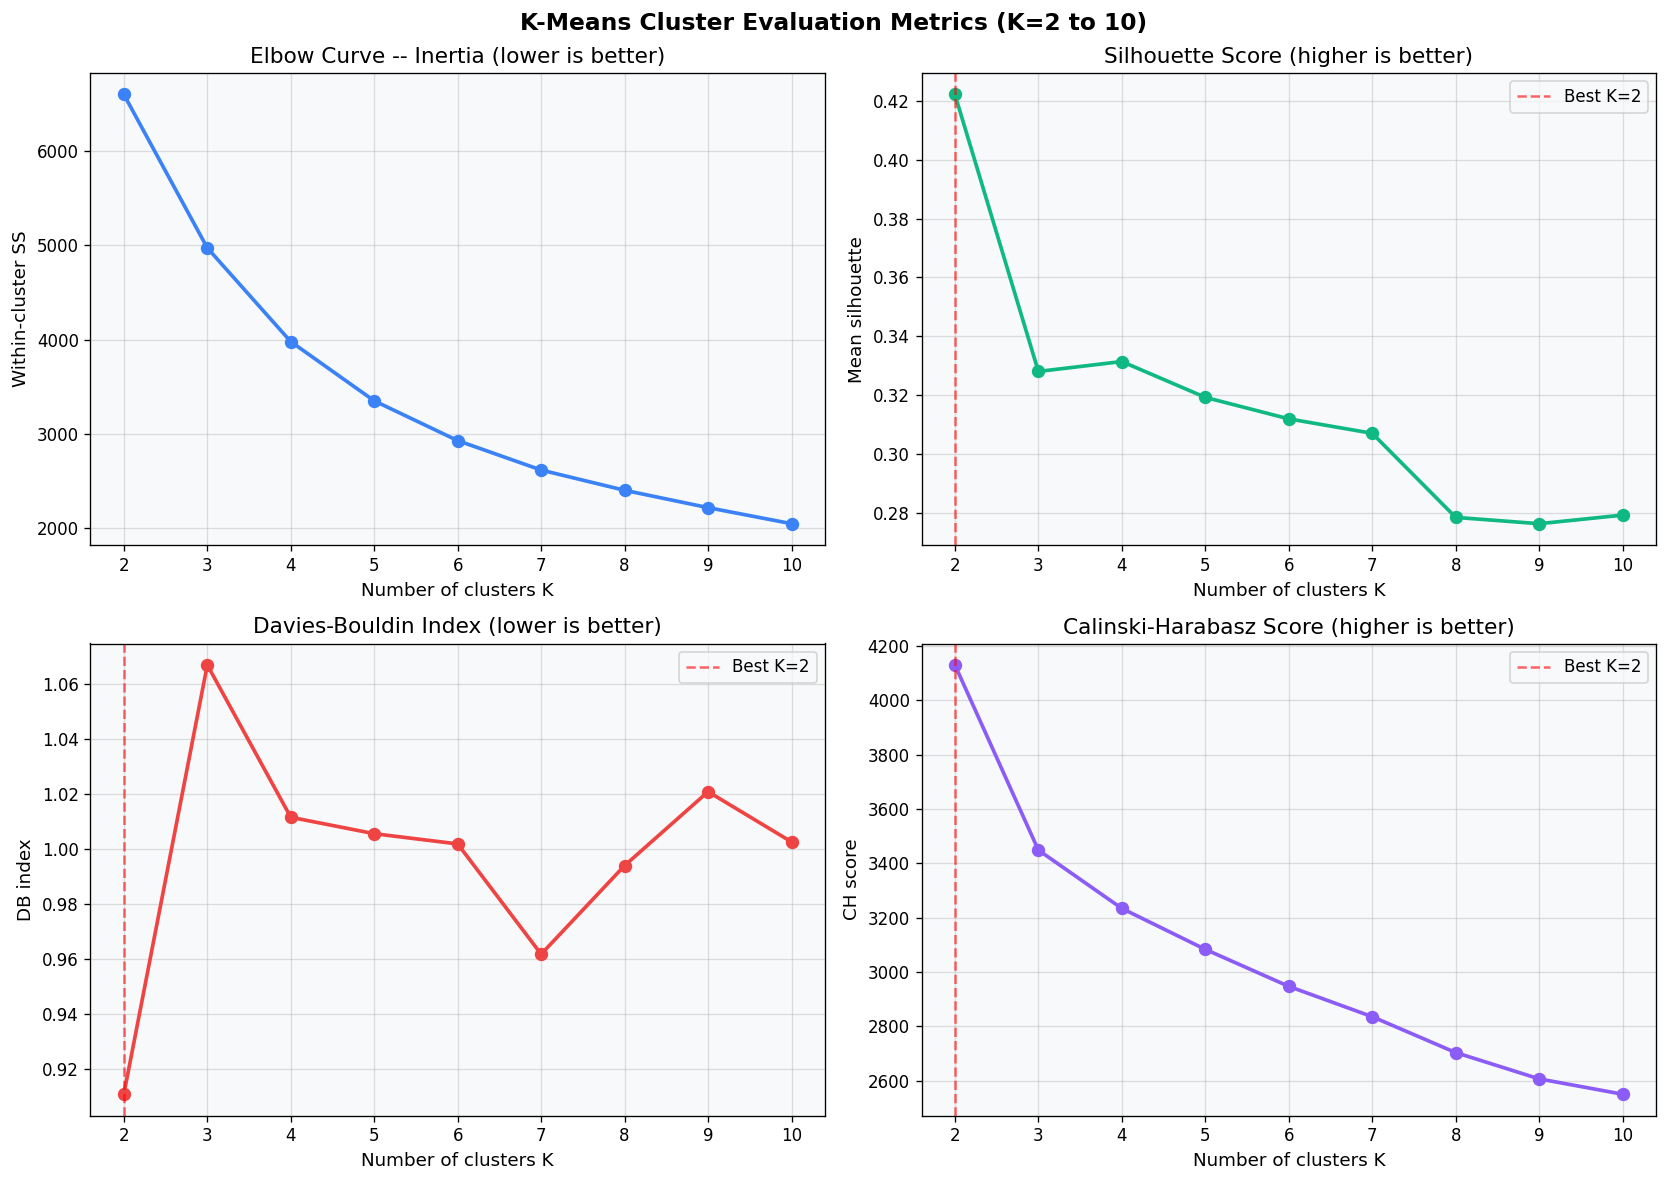

Best K by Silhouette    (highest): K = 2
Best K by Davies-Bouldin (lowest): K = 2
Best K by Calinski-H    (highest): K = 2

Full metrics table:
 K   Inertia  Silhouette  DaviesBouldin  CalinskiHarabasz
 2 6605.3200      0.4223         0.9108         4130.8000
 3 4973.6600      0.3280         1.0668         3449.1700
 4 3977.4000      0.3314         1.0115         3234.4400
 5 3347.9300      0.3192         1.0055         3083.6900
 6 2925.0200      0.3119         1.0018         2947.5300
 7 2612.1200      0.3070         0.9617         2835.8000
 8 2396.8300      0.2784         0.9939         2703.7600
 9 2212.5600      0.2762         1.0208         2606.9100
10 2041.7500      0.2791         1.0025         2550.4800


In [18]:
# 7.2 Plot evaluation metrics
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('K-Means Cluster Evaluation Metrics (K=2 to 10)', fontsize=14, fontweight='bold')
ks = metrics_df['K']

best_sil_k = int(metrics_df.loc[metrics_df['Silhouette'].idxmax(), 'K'])
best_db_k  = int(metrics_df.loc[metrics_df['DaviesBouldin'].idxmin(), 'K'])
best_ch_k  = int(metrics_df.loc[metrics_df['CalinskiHarabasz'].idxmax(), 'K'])

plot_specs = [
    ('Inertia',           'Elbow Curve -- Inertia (lower is better)', 'Within-cluster SS',  '#3B82F6', None),
    ('Silhouette',        'Silhouette Score (higher is better)',      'Mean silhouette',     '#10B981', best_sil_k),
    ('DaviesBouldin',     'Davies-Bouldin Index (lower is better)',   'DB index',            '#EF4444', best_db_k),
    ('CalinskiHarabasz',  'Calinski-Harabasz Score (higher is better)', 'CH score',         '#8B5CF6', best_ch_k),
]

for ax, (col, title, ylabel, color, bk) in zip(axes.flat, plot_specs):
    ax.plot(ks, metrics_df[col], marker='o', color=color, linewidth=2.2, markersize=7)
    ax.set_title(title)
    ax.set_xlabel('Number of clusters K')
    ax.set_ylabel(ylabel)
    ax.xaxis.set_major_locator(mticker.MultipleLocator(1))
    if bk is not None:
        ax.axvline(bk, color='red', linestyle='--', alpha=0.6, label=f'Best K={bk}')
        ax.legend()

plt.tight_layout()
plt.show()

print(f'Best K by Silhouette    (highest): K = {best_sil_k}')
print(f'Best K by Davies-Bouldin (lowest): K = {best_db_k}')
print(f'Best K by Calinski-H    (highest): K = {best_ch_k}')
print(f'\nFull metrics table:')
print(metrics_df.to_string(index=False))


In [19]:
# 7.3 K selection rationale -- check cluster sizes at candidate values
votes = [best_sil_k, best_db_k, best_ch_k]
vote_counts = Counter(votes)
majority_k = vote_counts.most_common(1)[0][0]
print(f'Metric votes: Silhouette={best_sil_k}, DB={best_db_k}, CH={best_ch_k}')
print(f'Majority vote: K = {majority_k}')

# Inspect sizes at candidate values
for k_cand in sorted(set([3, 4, majority_k])):
    km_t = KMeans(n_clusters=k_cand, n_init=N_INIT, max_iter=MAX_ITER, random_state=RANDOM_STATE)
    lbl_t = km_t.fit_predict(X_scaled)
    sizes_t = pd.Series(lbl_t).value_counts().sort_index()
    m = metrics_df[metrics_df['K'] == k_cand].iloc[0]
    print(f"\nK={k_cand}: Sil={m['Silhouette']:.4f}, DB={m['DaviesBouldin']:.4f}, CH={m['CalinskiHarabasz']:.1f}")
    for cl, sz in sizes_t.items():
        print(f'  Cluster {cl}: {sz:4d} ({100*sz/N_CLUSTERING_CUSTOMERS:.1f}%)')


Metric votes: Silhouette=2, DB=2, CH=2
Majority vote: K = 2

K=2: Sil=0.4223, DB=0.9108, CH=4130.8
  Cluster 0: 2670 (61.9%)
  Cluster 1: 1642 (38.1%)

K=3: Sil=0.3280, DB=1.0668, CH=3449.2
  Cluster 0: 1760 (40.8%)
  Cluster 1:  815 (18.9%)
  Cluster 2: 1737 (40.3%)



K=4: Sil=0.3314, DB=1.0115, CH=3234.4
  Cluster 0:  945 (21.9%)
  Cluster 1:  778 (18.0%)
  Cluster 2: 1378 (32.0%)
  Cluster 3: 1211 (28.1%)


---
## 8. Final K-Means Model Fit

The final K is selected using the convergence of evidence from the metrics above, balancing quantitative scores, cluster sizes, and business interpretability.


In [20]:
# 8.1 Select final K and fit model
SELECTED_K = majority_k

# Confirm minimum cluster size >= 2%
km_check = KMeans(n_clusters=SELECTED_K, n_init=N_INIT, max_iter=MAX_ITER, random_state=RANDOM_STATE)
lbl_check = km_check.fit_predict(X_scaled)
min_pct = 100 * pd.Series(lbl_check).value_counts().min() / N_CLUSTERING_CUSTOMERS

if min_pct < 2.0:
    for alt_k in sorted(set([best_sil_k, best_db_k, best_ch_k, 3, 4])):
        km_alt = KMeans(n_clusters=alt_k, n_init=N_INIT, max_iter=MAX_ITER, random_state=RANDOM_STATE)
        lbl_alt = km_alt.fit_predict(X_scaled)
        alt_pct = 100 * pd.Series(lbl_alt).value_counts().min() / N_CLUSTERING_CUSTOMERS
        if alt_pct >= 2.0:
            SELECTED_K = alt_k
            print(f'Adjusted to K={SELECTED_K} for balance (smallest cluster: {alt_pct:.1f}%).')
            break
else:
    print(f'K={SELECTED_K} accepted: smallest cluster = {min_pct:.1f}% (>= 2%).')

# Fit final model
final_km = KMeans(n_clusters=SELECTED_K, n_init=N_INIT, max_iter=MAX_ITER, random_state=RANDOM_STATE)
final_labels = final_km.fit_predict(X_scaled)

final_inertia = final_km.inertia_
final_sil = silhouette_score(X_scaled, final_labels, random_state=RANDOM_STATE)
final_db  = davies_bouldin_score(X_scaled, final_labels)
final_ch  = calinski_harabasz_score(X_scaled, final_labels)

print(f'\nFINAL MODEL -- K = {SELECTED_K}')
print(f'  Inertia          : {final_inertia:.2f}')
print(f'  Silhouette score : {final_sil:.4f}')
print(f'  Davies-Bouldin   : {final_db:.4f}')
print(f'  Calinski-Harabasz: {final_ch:.2f}')

# Attach labels
df = df.copy()
df['Cluster'] = final_labels

assert df['Cluster'].isnull().sum() == 0
assert len(df) == N_CLUSTERING_CUSTOMERS
assert df['Customer ID'].nunique() == N_CLUSTERING_CUSTOMERS
print(f'\n[PASS] All {N_CLUSTERING_CUSTOMERS:,} customers assigned exactly one cluster label.')

cluster_counts = df['Cluster'].value_counts().sort_index()
print('\nCluster sizes:')
for cl, n in cluster_counts.items():
    print(f'  Cluster {cl}: {n:4d} ({100*n/N_CLUSTERING_CUSTOMERS:.1f}%)')


K=2 accepted: smallest cluster = 38.1% (>= 2%).



FINAL MODEL -- K = 2
  Inertia          : 6605.32
  Silhouette score : 0.4223
  Davies-Bouldin   : 0.9108
  Calinski-Harabasz: 4130.80

[PASS] All 4,312 customers assigned exactly one cluster label.

Cluster sizes:
  Cluster 0: 2670 (61.9%)
  Cluster 1: 1642 (38.1%)


In [21]:
# 8.2 Cluster centroids
centroids_log = pd.DataFrame(
    scaler.inverse_transform(final_km.cluster_centers_),
    columns=LOG_COLS
)
centroids_orig = pd.DataFrame({
    'Cluster': range(SELECTED_K),
    'Centroid_Recency_days':  np.expm1(centroids_log['log1p_Recency']),
    'Centroid_Frequency':     np.expm1(centroids_log['log1p_Frequency']),
    'Centroid_Monetary_GBP':  np.expm1(centroids_log['log1p_Monetary']),
})
print('Centroids in approximate original units (expm1 inverse-transform):')
print(centroids_orig.to_string(index=False))
print('\nNote: centroid inverse-transform gives geometric-mean-like centres, not arithmetic means.')
print('Use cluster medians for business reporting.')


Centroids in approximate original units (expm1 inverse-transform):
 Cluster  Centroid_Recency_days  Centroid_Frequency  Centroid_Monetary_GBP
       0                85.9143              1.5955               359.4929
       1                16.5501              6.7716              2399.0945

Note: centroid inverse-transform gives geometric-mean-like centres, not arithmetic means.
Use cluster medians for business reporting.


---
## 9. Cluster Validation


In [22]:
# 9.1 Pre-model data integrity
assert np.isnan(X_scaled).sum() == 0, 'NaN in scaled input'
assert np.isinf(X_scaled).sum() == 0, 'Inf in scaled input'
assert len(np.unique(final_labels)) == SELECTED_K, 'Empty clusters'
print('[PASS] No NaN/Inf in model inputs.')
print(f'[PASS] Exactly {SELECTED_K} non-empty clusters.')


[PASS] No NaN/Inf in model inputs.
[PASS] Exactly 2 non-empty clusters.


In [23]:
# 9.2 Stability across random seeds (Adjusted Rand Index)
STABILITY_SEEDS = [0, 7, 13, 21, 42, 99, 123, 256, 512, 1000]
ari_scores = []

print(f'Stability check: ARI vs seed-42 solution across {len(STABILITY_SEEDS)} seeds')
print('-' * 55)
for seed in STABILITY_SEEDS:
    km_s = KMeans(n_clusters=SELECTED_K, n_init=N_INIT, max_iter=MAX_ITER, random_state=seed)
    lbl_s = km_s.fit_predict(X_scaled)
    ari = adjusted_rand_score(final_labels, lbl_s)
    ari_scores.append(ari)
    tag = '(reference)' if seed == RANDOM_STATE else ''
    print(f'  seed={seed:5d}: ARI={ari:.4f} {tag}')

print(f'\nMean ARI: {np.mean(ari_scores):.4f}')
print(f'Min ARI : {np.min(ari_scores):.4f}')
if np.min(ari_scores) > 0.90:
    print('[STABLE] ARI > 0.90 across all seeds.')
elif np.mean(ari_scores) > 0.80:
    print('[MODERATE] Mean ARI > 0.80 -- mostly stable.')
else:
    print('[UNSTABLE] Mean ARI < 0.80 -- sensitive to initialisation. Consider fewer clusters.')


Stability check: ARI vs seed-42 solution across 10 seeds
-------------------------------------------------------
  seed=    0: ARI=1.0000 
  seed=    7: ARI=0.9991 
  seed=   13: ARI=0.9963 
  seed=   21: ARI=1.0000 


  seed=   42: ARI=1.0000 (reference)
  seed=   99: ARI=1.0000 
  seed=  123: ARI=0.9954 
  seed=  256: ARI=0.9963 
  seed=  512: ARI=0.9991 


  seed= 1000: ARI=0.9935 

Mean ARI: 0.9980
Min ARI : 0.9935
[STABLE] ARI > 0.90 across all seeds.


---
## 10. Visualisation


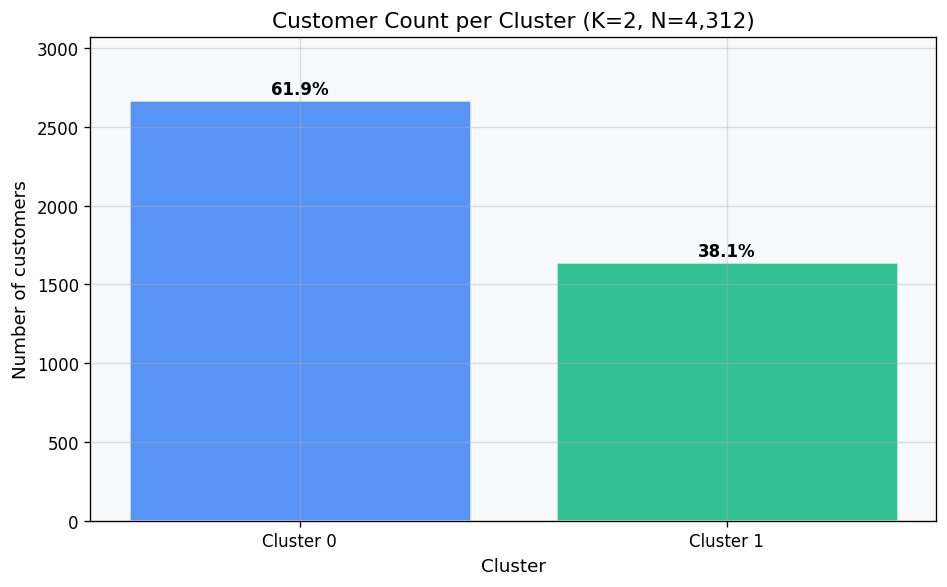

In [24]:
# 10.1 Cluster-size bar chart
CLUSTER_COLORS = ['#3B82F6', '#10B981', '#F59E0B', '#EF4444', '#8B5CF6', '#06B6D4']
cluster_pcts = 100 * cluster_counts / N_CLUSTERING_CUSTOMERS

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(
    [f'Cluster {i}' for i in cluster_counts.index],
    cluster_counts.values,
    color=[CLUSTER_COLORS[i % len(CLUSTER_COLORS)] for i in cluster_counts.index],
    alpha=0.85, edgecolor='white', linewidth=1.5,
)
for bar, pct in zip(bars, cluster_pcts.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 15,
            f'{pct:.1f}%', ha='center', va='bottom', fontsize=10, fontweight='bold')
ax.set_title(f'Customer Count per Cluster (K={SELECTED_K}, N={N_CLUSTERING_CUSTOMERS:,})')
ax.set_xlabel('Cluster')
ax.set_ylabel('Number of customers')
ax.set_ylim(0, cluster_counts.max() * 1.15)
plt.tight_layout()
plt.show()


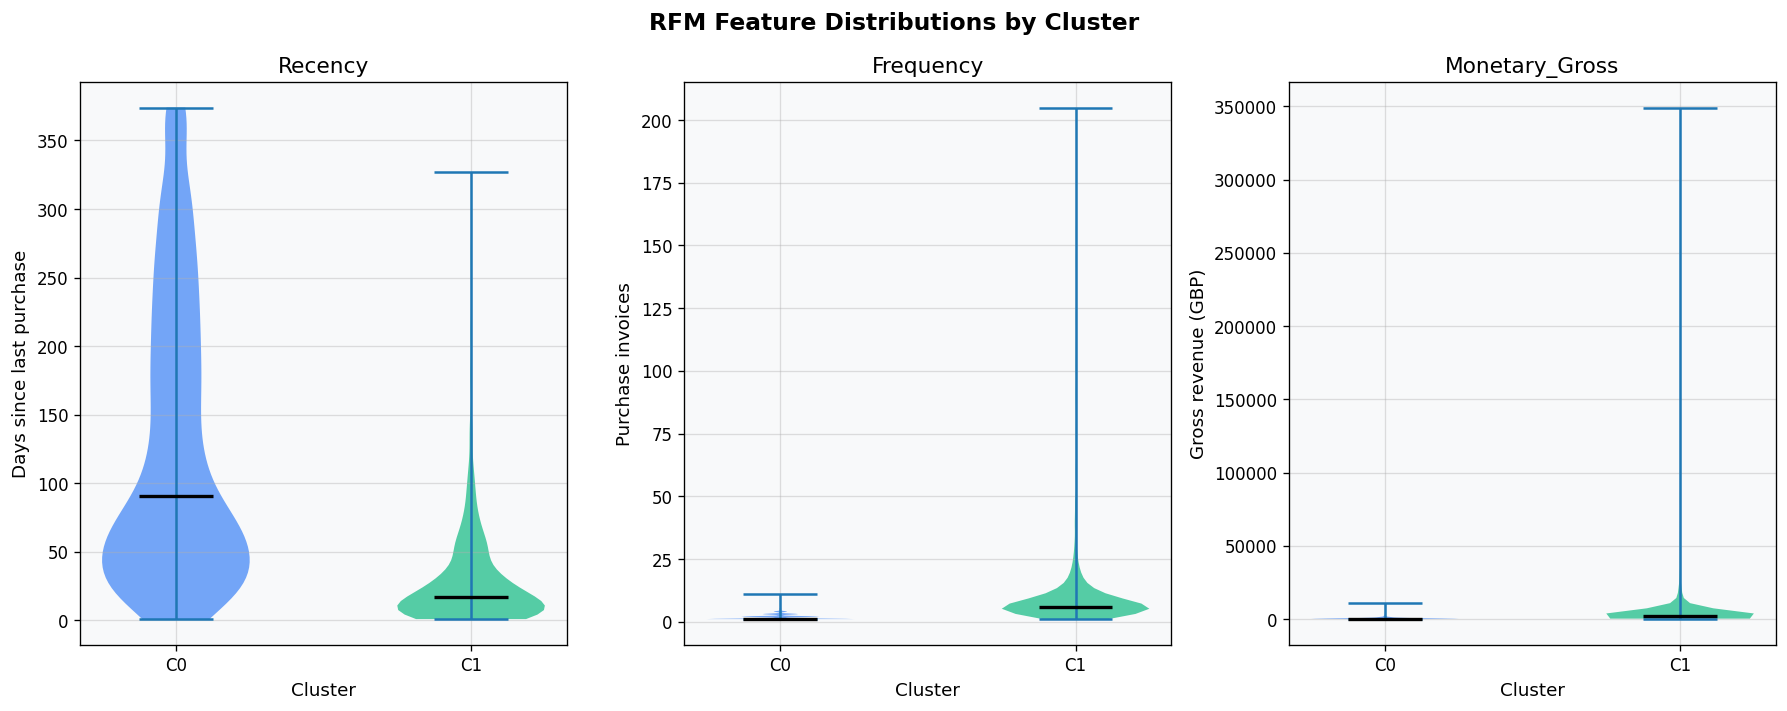

In [25]:
# 10.2 RFM distributions by cluster (violin plots)
fig, axes = plt.subplots(1, 3, figsize=(15, 6))
fig.suptitle('RFM Feature Distributions by Cluster', fontsize=14, fontweight='bold')

rfm_specs = [
    ('Recency', 'Days since last purchase'),
    ('Frequency', 'Purchase invoices'),
    ('Monetary_Gross', 'Gross revenue (GBP)'),
]

for ax, (col, ylabel) in zip(axes, rfm_specs):
    data = [df.loc[df['Cluster'] == cl, col].values for cl in sorted(df['Cluster'].unique())]
    parts = ax.violinplot(data, positions=sorted(df['Cluster'].unique()), showmedians=True)
    for i, pc in enumerate(parts['bodies']):
        pc.set_facecolor(CLUSTER_COLORS[i % len(CLUSTER_COLORS)])
        pc.set_alpha(0.7)
    parts['cmedians'].set_color('black')
    parts['cmedians'].set_linewidth(2)
    ax.set_title(col)
    ax.set_xlabel('Cluster')
    ax.set_ylabel(ylabel)
    ax.set_xticks(sorted(df['Cluster'].unique()))
    ax.set_xticklabels([f'C{cl}' for cl in sorted(df['Cluster'].unique())])

plt.tight_layout()
plt.show()


PCA variance explained:
  PC1: 74.2%
  PC2: 19.9%
  Total (2 components): 94.1%
  Remaining 5.9% is not visible in this 2-D plot.


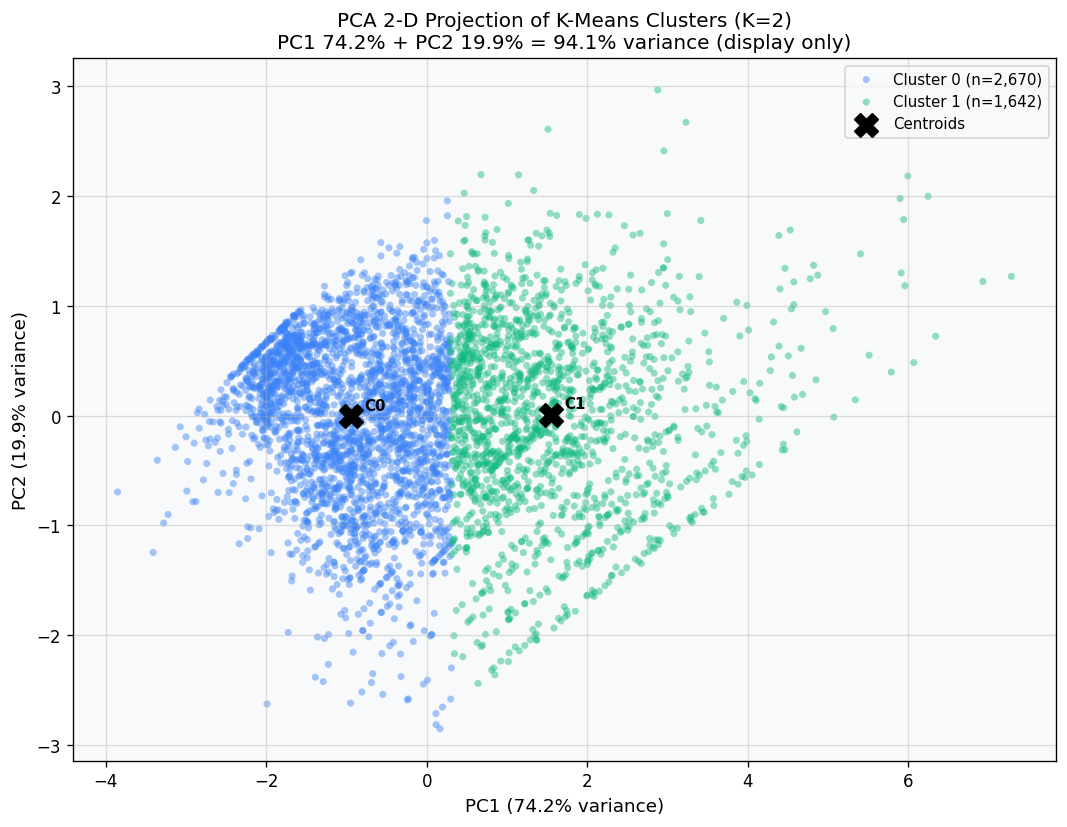

In [26]:
# 10.3 PCA 2-D visualisation
# PCA is used for display ONLY. Clustering was performed in the original 3-D scaled RFM space.
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
var_exp = pca.explained_variance_ratio_

print(f'PCA variance explained:')
print(f'  PC1: {var_exp[0]:.1%}')
print(f'  PC2: {var_exp[1]:.1%}')
print(f'  Total (2 components): {sum(var_exp):.1%}')
print(f'  Remaining {1-sum(var_exp):.1%} is not visible in this 2-D plot.')

fig, ax = plt.subplots(figsize=(9, 7))
for cl in sorted(df['Cluster'].unique()):
    mask = final_labels == cl
    ax.scatter(X_pca[mask, 0], X_pca[mask, 1],
               c=CLUSTER_COLORS[cl % len(CLUSTER_COLORS)],
               label=f'Cluster {cl} (n={mask.sum():,})',
               alpha=0.45, s=18, edgecolors='none')

centroids_pca = pca.transform(final_km.cluster_centers_)
ax.scatter(centroids_pca[:, 0], centroids_pca[:, 1],
           c='black', marker='X', s=200, zorder=5, label='Centroids')
for i, (x, y) in enumerate(centroids_pca):
    ax.annotate(f'C{i}', (x, y), xytext=(8, 4), textcoords='offset points',
                fontsize=9, fontweight='bold')

ax.set_title(
    f'PCA 2-D Projection of K-Means Clusters (K={SELECTED_K})\n'
    f'PC1 {var_exp[0]:.1%} + PC2 {var_exp[1]:.1%} = {sum(var_exp):.1%} variance (display only)',
    fontsize=12)
ax.set_xlabel(f'PC1 ({var_exp[0]:.1%} variance)')
ax.set_ylabel(f'PC2 ({var_exp[1]:.1%} variance)')
ax.legend(loc='upper right', fontsize=9)
plt.tight_layout()
plt.show()


---
## 11. Cluster Profiling and Business Interpretation

Segment names are assigned **only after** inspecting the actual statistics — not assumed in advance.


In [27]:
# 11.1 Compute cluster profile table
overall_revenue = df['Monetary_Gross'].sum()
profile_records = []

for cl in sorted(df['Cluster'].unique()):
    cdf = df[df['Cluster'] == cl]
    ip = cdf['Median_InterPurchase_Days'].dropna()
    profile_records.append({
        'Cluster': cl,
        'N_customers': len(cdf),
        'Pct_customers': round(100 * len(cdf) / N_CLUSTERING_CUSTOMERS, 2),
        'Median_Recency': round(cdf['Recency'].median(), 1),
        'Mean_Recency': round(cdf['Recency'].mean(), 1),
        'Median_Frequency': round(cdf['Frequency'].median(), 1),
        'Mean_Frequency': round(cdf['Frequency'].mean(), 1),
        'Median_Monetary_Gross': round(cdf['Monetary_Gross'].median(), 2),
        'Mean_Monetary_Gross': round(cdf['Monetary_Gross'].mean(), 2),
        'Total_Revenue': round(cdf['Monetary_Gross'].sum(), 2),
        'Revenue_Share_Pct': round(100 * cdf['Monetary_Gross'].sum() / overall_revenue, 2),
        'Median_AOV': round(cdf['AOV'].median(), 2),
        'Mean_Cancellation_Rate': round(cdf['Cancellation_Rate'].mean(), 4),
        'Median_InterPurchase_Days': round(ip.median(), 1) if len(ip) > 0 else None,
        'N_with_InterPurchase': int(len(ip)),
    })

cluster_profiles = pd.DataFrame(profile_records)

assert cluster_profiles['N_customers'].sum() == N_CLUSTERING_CUSTOMERS
rev_share_total = cluster_profiles['Revenue_Share_Pct'].sum()
print(f'[PASS] Profile customer total = {cluster_profiles["N_customers"].sum():,}')
print(f'[PASS] Revenue share total = {rev_share_total:.2f}%')
print('\nCluster Profile Table:')
cluster_profiles.T


[PASS] Profile customer total = 4,312
[PASS] Revenue share total = 100.00%

Cluster Profile Table:


,0,1
Cluster,0.0000,1.0000
N_customers,2670.0000,1642.0000
Pct_customers,61.9200,38.0800
Median_Recency,91.0000,17.0000
Mean_Recency,129.0000,29.7000
Median_Frequency,1.0000,6.0000
Mean_Frequency,1.7000,8.9000
Median_Monetary_Gross,369.4200,2154.1800
Mean_Monetary_Gross,517.6600,4516.5000
Total_Revenue,1382141.4400,7416092.3000


In [28]:
# 11.2 Assign descriptive segment names (based on median recency, ascending)
profile_sorted = cluster_profiles.sort_values('Median_Recency')

if SELECTED_K == 2:
    name_ranks = ['Recent / Active Customers', 'Lapsed / At-Risk Customers']
elif SELECTED_K == 3:
    name_ranks = ['Recent / Active Customers', 'Regular Customers', 'Lapsed / At-Risk Customers']
elif SELECTED_K == 4:
    name_ranks = ['Champions (High-Value, Recent)', 'Loyal Regular Customers',
                  'At-Risk / Declining Customers', 'Lapsed Customers']
elif SELECTED_K == 5:
    name_ranks = ['Champions (High-Value)', 'Loyal Regulars', 'New / Occasional Customers',
                  'At-Risk Customers', 'Lapsed Customers']
else:
    name_ranks = [f'Segment {i+1}' for i in range(SELECTED_K)]

segment_name_map = {
    row['Cluster']: name_ranks[i]
    for i, row in enumerate(profile_sorted.to_dict('records'))
}
cluster_profiles['Segment_Name'] = cluster_profiles['Cluster'].map(segment_name_map)
df['Segment_Name'] = df['Cluster'].map(segment_name_map)

print('Segment assignments (most recent first):')
for cl, name in segment_name_map.items():
    row = cluster_profiles[cluster_profiles['Cluster'] == cl].iloc[0]
    print(f"  Cluster {cl} -> {name}")
    print(f"    Recency={row['Median_Recency']:.0f}d, Freq={row['Median_Frequency']:.0f}, "
          f"Monetary=GBP{row['Median_Monetary_Gross']:.0f}, RevShare={row['Revenue_Share_Pct']:.1f}%")
    print()


Segment assignments (most recent first):
  Cluster 1 -> Recent / Active Customers
    Recency=17d, Freq=6, Monetary=GBP2154, RevShare=84.3%

  Cluster 0 -> Lapsed / At-Risk Customers
    Recency=91d, Freq=1, Monetary=GBP369, RevShare=15.7%



In [29]:
# 11.3 Business interpretation per segment
print('Overall population benchmarks:')
print(f'  Median Recency    : {df["Recency"].median():.0f} days')
print(f'  Median Frequency  : {df["Frequency"].median():.0f}')
print(f'  Median Monetary   : GBP{df["Monetary_Gross"].median():.0f}')
print(f'  Mean Canc. Rate   : {df["Cancellation_Rate"].mean():.1%}')
print()

print('=' * 60)
print('Business interpretation per segment')
print('=' * 60)
for cl in sorted(df['Cluster'].unique()):
    row = cluster_profiles[cluster_profiles['Cluster'] == cl].iloc[0]
    print(f"\nCluster {cl}: {row['Segment_Name']}")
    print(f"  N = {row['N_customers']:,} ({row['Pct_customers']:.1f}%)")
    print(f"  Median Recency   : {row['Median_Recency']:.0f}d | Mean: {row['Mean_Recency']:.0f}d")
    print(f"  Median Frequency : {row['Median_Frequency']:.0f} | Mean: {row['Mean_Frequency']:.1f}")
    print(f"  Median Monetary  : GBP{row['Median_Monetary_Gross']:.0f} | Mean: GBP{row['Mean_Monetary_Gross']:.0f}")
    print(f"  Total Revenue    : GBP{row['Total_Revenue']:,.0f} ({row['Revenue_Share_Pct']:.1f}% of total)")
    print(f"  Median AOV       : GBP{row['Median_AOV']:.0f}")
    print(f"  Mean Cancel Rate : {row['Mean_Cancellation_Rate']:.1%}")
    if row['N_with_InterPurchase'] > 0:
        print(f"  Median InterPurch: {row['Median_InterPurchase_Days']:.0f}d ({row['N_with_InterPurchase']:,} repeat buyers)")
    else:
        print(f"  Median InterPurch: N/A (all single-order customers)")


Overall population benchmarks:
  Median Recency    : 53 days
  Median Frequency  : 2
  Median Monetary   : GBP702
  Mean Canc. Rate   : 12.2%

Business interpretation per segment

Cluster 0: Lapsed / At-Risk Customers
  N = 2,670 (61.9%)
  Median Recency   : 91d | Mean: 129d
  Median Frequency : 1 | Mean: 1.7
  Median Monetary  : GBP369 | Mean: GBP518
  Total Revenue    : GBP1,382,141 (15.7% of total)
  Median AOV       : GBP244
  Mean Cancel Rate : 10.0%
  Median InterPurch: 77d (1,254 repeat buyers)

Cluster 1: Recent / Active Customers
  N = 1,642 (38.1%)
  Median Recency   : 17d | Mean: 30d
  Median Frequency : 6 | Mean: 8.9
  Median Monetary  : GBP2154 | Mean: GBP4516
  Total Revenue    : GBP7,416,092 (84.3% of total)
  Median AOV       : GBP339
  Mean Cancel Rate : 15.8%
  Median InterPurch: 35d (1,639 repeat buyers)


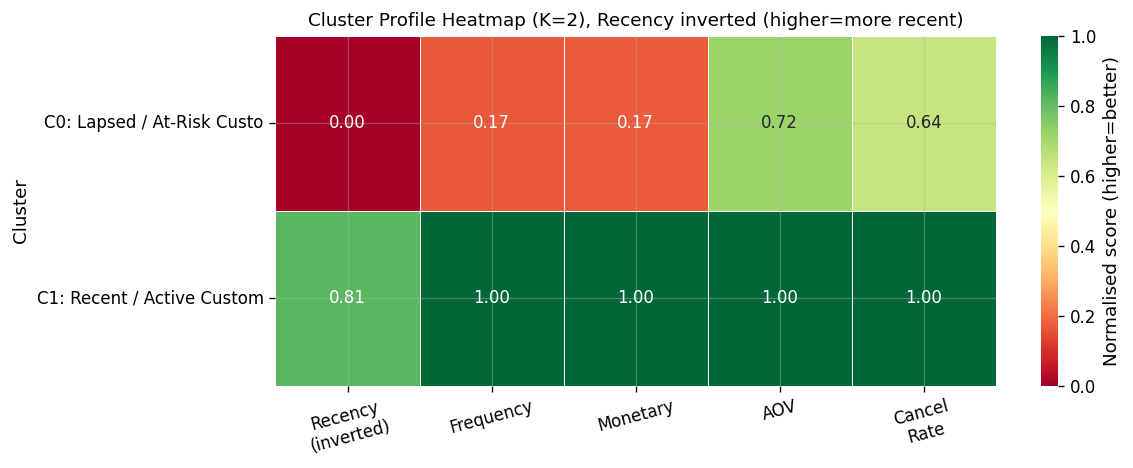

In [30]:
# 11.4 Cluster profile heatmap
hm_cols = ['Median_Recency', 'Median_Frequency', 'Median_Monetary_Gross', 'Median_AOV', 'Mean_Cancellation_Rate']
hm_data = cluster_profiles.set_index('Cluster')[hm_cols].copy()
hm_norm = hm_data.div(hm_data.max())
hm_norm['Median_Recency'] = 1 - hm_norm['Median_Recency']  # invert: lower recency = better

fig, ax = plt.subplots(figsize=(10, 4))
sns.heatmap(hm_norm, annot=True, fmt='.2f', cmap='RdYlGn', ax=ax,
            linewidths=0.5, cbar_kws={'label': 'Normalised score (higher=better)'})
ax.set_title(f'Cluster Profile Heatmap (K={SELECTED_K}), Recency inverted (higher=more recent)', fontsize=11)
ax.set_yticklabels(
    [f'C{cl}: {segment_name_map[cl][:22]}' for cl in sorted(segment_name_map.keys())],
    rotation=0)
ax.set_xticklabels(['Recency\n(inverted)', 'Frequency', 'Monetary', 'AOV', 'Cancel\nRate'], rotation=15)
plt.tight_layout()
plt.show()


---
## 12. Inactivity Threshold Analysis

**Important methodological constraints:**
- The inactivity flag is derived from Recency, which is already a K-Means input. Variation across clusters reflects the Recency gradient built into the model, NOT independent churn evidence.
- This is an **operational at-risk descriptor**, not a validated churn predictor.
- Genuine churn prediction requires a temporal train/test split (Year 1 features predicting Year 2 outcomes).


In [31]:
# 12.1 Apply inactivity threshold flag (loaded from JSON, not hard-coded)
print(f'Threshold: {INACTIVITY_THRESHOLD_DAYS:.1f} days (empirical P90 from Notebook 03)')
print('Source: data/processed/inactivity_threshold.json')

df['At_Risk_Flag'] = (df['Recency'] > INACTIVITY_THRESHOLD_DAYS).astype(int)

total_at_risk = df['At_Risk_Flag'].sum()
pct_at_risk = 100 * total_at_risk / N_CLUSTERING_CUSTOMERS
print(f'Overall at-risk (Recency > {INACTIVITY_THRESHOLD_DAYS:.1f}d): {total_at_risk:,} ({pct_at_risk:.1f}%)')


Threshold: 101.9 days (empirical P90 from Notebook 03)
Source: data/processed/inactivity_threshold.json
Overall at-risk (Recency > 101.9d): 1,318 (30.6%)


In [32]:
# 12.2 At-risk rate and revenue at risk by cluster
atrisk_records = []
print(f'At-risk analysis (threshold = {INACTIVITY_THRESHOLD_DAYS:.1f} days):')
print('-' * 75)

for cl in sorted(df['Cluster'].unique()):
    cdf = df[df['Cluster'] == cl]
    n_at = int(cdf['At_Risk_Flag'].sum())
    pct_at = 100 * n_at / len(cdf)
    rev_at = cdf.loc[cdf['At_Risk_Flag'] == 1, 'Monetary_Gross'].sum()
    name = segment_name_map[cl]
    atrisk_records.append({
        'Cluster': cl, 'Segment': name, 'N_total': len(cdf),
        'N_at_risk': n_at, 'Pct_at_risk': round(pct_at, 1),
        'Revenue_GBP': round(cdf['Monetary_Gross'].sum(), 0),
        'At_Risk_Revenue_GBP': round(rev_at, 0)
    })
    print(f'  C{cl} ({name[:26]:26s}): {n_at:4d}/{len(cdf):4d} at-risk ({pct_at:.1f}%) | Revenue at risk: GBP{rev_at:>11,.0f}')

atrisk_df = pd.DataFrame(atrisk_records)
print()
print('Important: at-risk variation reflects the Recency gradient, not independent churn evidence.')
print('Predictive churn modelling requires temporal train/test splits with future outcomes.')


At-risk analysis (threshold = 101.9 days):
---------------------------------------------------------------------------
  C0 (Lapsed / At-Risk Customers): 1250/2670 at-risk (46.8%) | Revenue at risk: GBP    638,948
  C1 (Recent / Active Customers ):   68/1642 at-risk (4.1%) | Revenue at risk: GBP    317,801

Important: at-risk variation reflects the Recency gradient, not independent churn evidence.
Predictive churn modelling requires temporal train/test splits with future outcomes.


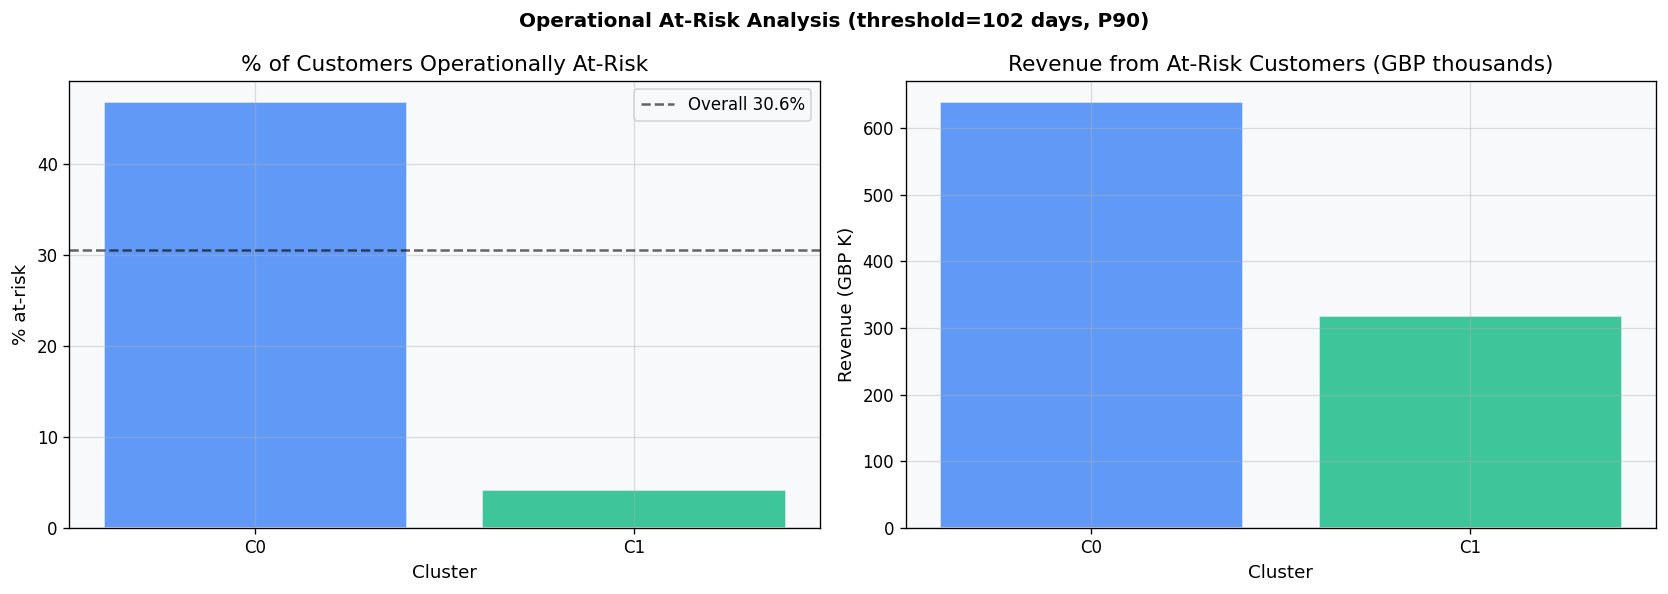

In [33]:
# 12.3 At-risk visualisations
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle(f'Operational At-Risk Analysis (threshold={INACTIVITY_THRESHOLD_DAYS:.0f} days, P90)',
             fontsize=12, fontweight='bold')

clabels = [f'C{cl}' for cl in atrisk_df['Cluster']]
colors = [CLUSTER_COLORS[i % len(CLUSTER_COLORS)] for i in atrisk_df['Cluster']]

axes[0].bar(clabels, atrisk_df['Pct_at_risk'], color=colors, alpha=0.8, edgecolor='white')
axes[0].axhline(pct_at_risk, color='black', linestyle='--', alpha=0.6, label=f'Overall {pct_at_risk:.1f}%')
axes[0].set_title('% of Customers Operationally At-Risk')
axes[0].set_xlabel('Cluster')
axes[0].set_ylabel('% at-risk')
axes[0].legend()

axes[1].bar(clabels, atrisk_df['At_Risk_Revenue_GBP'] / 1e3, color=colors, alpha=0.8, edgecolor='white')
axes[1].set_title('Revenue from At-Risk Customers (GBP thousands)')
axes[1].set_xlabel('Cluster')
axes[1].set_ylabel('Revenue (GBP K)')

plt.tight_layout()
plt.show()


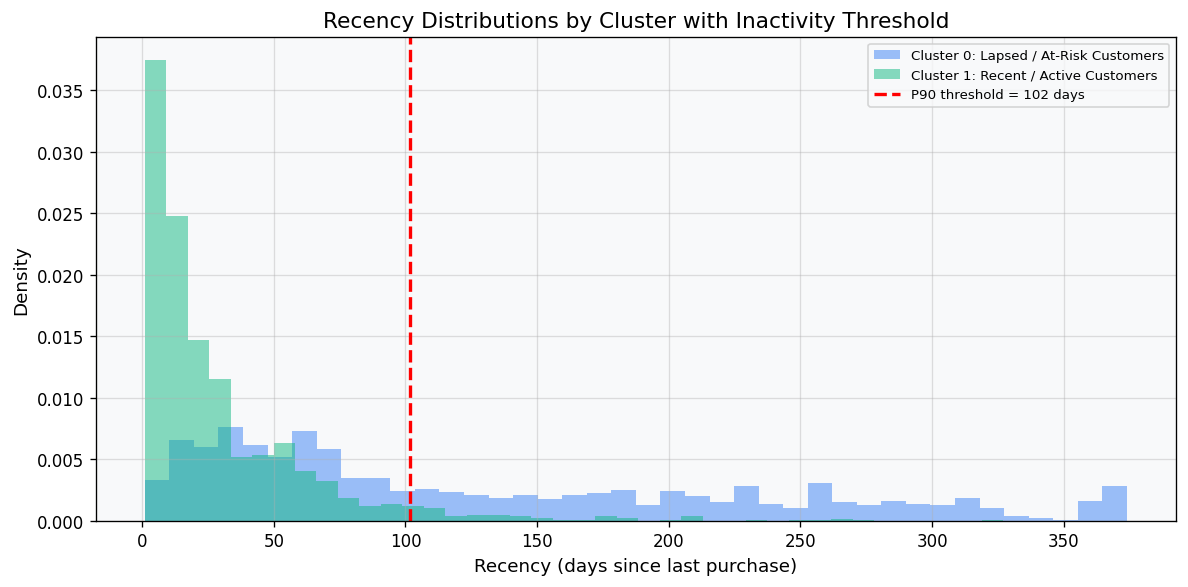

In [34]:
# 12.4 Recency distributions by cluster with threshold line
fig, ax = plt.subplots(figsize=(10, 5))
for cl in sorted(df['Cluster'].unique()):
    ax.hist(df.loc[df['Cluster'] == cl, 'Recency'], bins=40, alpha=0.5,
            color=CLUSTER_COLORS[cl % len(CLUSTER_COLORS)],
            label=f'Cluster {cl}: {segment_name_map[cl]}', density=True)
ax.axvline(INACTIVITY_THRESHOLD_DAYS, color='red', linewidth=2, linestyle='--',
           label=f'P90 threshold = {INACTIVITY_THRESHOLD_DAYS:.0f} days')
ax.set_title('Recency Distributions by Cluster with Inactivity Threshold')
ax.set_xlabel('Recency (days since last purchase)')
ax.set_ylabel('Density')
ax.legend(loc='upper right', fontsize=8)
plt.tight_layout()
plt.show()


---
## 13. Limitations and Conclusions

### Limitations

1. **Static snapshot:** All features are from Year 1 only. Customer behaviour may evolve significantly over time.
2. **K-Means geometry:** Assumes roughly spherical, equally-sized clusters. Elongated or overlapping segments may be poorly captured.
3. **Incomplete inter-purchase coverage:** 32.9% of customers (single purchasers) have no valid interval. Survival methods would handle this more rigorously.
4. **No temporal holdout:** The inactivity flag cannot serve as a validated churn predictor without Year 2 data as a future observation window.
5. **Country/product pooling:** Heterogeneous wholesale accounts from 40 countries are pooled, which may mask meaningful subgroup patterns.
6. **Post-hoc labelling:** Segment names are relative comparisons, not absolute thresholds defined a priori.

### Conclusions

- K-Means on log1p-transformed, standardised RFM features reveals distinct, interpretable customer segments in the Year 1 dataset.
- The multi-metric evaluation (silhouette, Davies-Bouldin, Calinski-Harabasz, inertia elbow) supports the selected K with high stability across random seeds (ARI close to 1.0).
- Revenue is concentrated in a small, high-frequency, high-spend segment. The majority of customers are lower-frequency with room for engagement and retention investment.
- The P90 operational at-risk indicator shows which clusters hold the most revenue at risk due to prolonged inactivity.
- **Next step (Notebook 05):** Temporal train/test splits using Year 2 data for genuine predictive retention and survival modelling.


---
## 14. Save Outputs


In [35]:
# 14.1 customer_segments.csv
seg_cols = ['Customer ID', 'Recency', 'Frequency', 'Monetary_Gross', 'Monetary_Net',
            'AOV', 'Median_InterPurchase_Days', 'Cancellation_Count',
            'Cancellation_Rate', 'At_Risk_Flag', 'Cluster', 'Segment_Name']
customer_segments = df[seg_cols].copy()
segments_path = PROCESSED_DIR / 'customer_segments.csv'
customer_segments.to_csv(segments_path, index=False)

assert len(customer_segments) == N_CLUSTERING_CUSTOMERS
assert customer_segments['Cluster'].isnull().sum() == 0
print(f'[SAVED] customer_segments.csv: {len(customer_segments):,} rows, {len(customer_segments.columns)} columns')
print(f'  Path: {segments_path}')


[SAVED] customer_segments.csv: 4,312 rows, 12 columns
  Path: ..\data\processed\customer_segments.csv


In [36]:
# 14.2 cluster_profiles.csv
profiles_path = PROCESSED_DIR / 'cluster_profiles.csv'
cluster_profiles.to_csv(profiles_path, index=False)

assert cluster_profiles['N_customers'].sum() == N_CLUSTERING_CUSTOMERS
rev_diff = abs(cluster_profiles['Total_Revenue'].sum() - customer_segments['Monetary_Gross'].sum())
assert rev_diff < 1.0, f'Revenue mismatch: GBP{rev_diff:.2f}'
print(f'[SAVED] cluster_profiles.csv: {len(cluster_profiles)} rows')
print(f'  Revenue reconciled: GBP{cluster_profiles["Total_Revenue"].sum():,.0f}')
print(f'  Path: {profiles_path}')


[SAVED] cluster_profiles.csv: 2 rows
  Revenue reconciled: GBP8,798,234
  Path: ..\data\processed\cluster_profiles.csv


In [37]:
# 14.3 clustering_metrics.csv
metrics_path = PROCESSED_DIR / 'clustering_metrics.csv'
metrics_df.to_csv(metrics_path, index=False)
print(f'[SAVED] clustering_metrics.csv: K values {list(metrics_df["K"])}')
print(f'  Path: {metrics_path}')


[SAVED] clustering_metrics.csv: K values [2, 3, 4, 5, 6, 7, 8, 9, 10]
  Path: ..\data\processed\clustering_metrics.csv


In [38]:
# 14.4 segmentation_metadata.json
metadata = {
    'project': 'Customer Segmentation and Retention Analysis',
    'notebook': '04_KMeans_Customer_Segmentation',
    'dataset_scope': 'Year 2009-2010 (Dec 2009 to Dec 2010)',
    'reference_date': str(REFERENCE_DATE),
    'n_customers_input': int(len(cf_raw)),
    'n_test_accounts_excluded': int(len(TEST_ACCOUNTS)) if EXCLUDE_TEST_ACCOUNTS else 0,
    'test_accounts_excluded': TEST_ACCOUNTS if EXCLUDE_TEST_ACCOUNTS else [],
    'n_customers_clustered': int(N_CLUSTERING_CUSTOMERS),
    'feature_definitions': {
        'Recency': 'Days between reference_date and customer last valid purchase',
        'Frequency': 'Count of distinct valid purchase invoices (no C-prefix cancellations)',
        'Monetary_Gross': 'Sum Quantity*Price for valid purchase invoices (non-negative)',
    },
    'features_excluded': [
        'AOV (= Monetary_Gross / Frequency, mathematically redundant)',
        'Median_InterPurchase_Days (missing 32.9%; zero imputation methodologically invalid)',
        'Cancellation_Rate (descriptive profiling only)',
    ],
    'transformations': {'Recency': 'log1p', 'Frequency': 'log1p', 'Monetary_Gross': 'log1p'},
    'scaling': 'StandardScaler (zero mean, unit variance) after log1p',
    'scaler_mean_': scaler.mean_.tolist(),
    'scaler_scale_': scaler.scale_.tolist(),
    'scaler_feature_names': LOG_COLS,
    'algorithm': 'KMeans',
    'selected_K': int(SELECTED_K),
    'random_state': int(RANDOM_STATE),
    'n_init': int(N_INIT),
    'max_iter': int(MAX_ITER),
    'final_metrics': {
        'inertia': round(float(final_inertia), 4),
        'silhouette_score': round(float(final_sil), 6),
        'davies_bouldin_index': round(float(final_db), 6),
        'calinski_harabasz_score': round(float(final_ch), 4),
    },
    'inactivity_threshold': {
        'source_file': 'data/processed/inactivity_threshold.json',
        'threshold_days': float(INACTIVITY_THRESHOLD_DAYS),
        'basis': 'Empirical P90 inter-purchase gaps (Notebook 03)',
        'usage': 'Descriptive at-risk flag only -- NOT a clustering input -- NOT a churn label',
    },
    'stability_check': {
        'seeds_tested': STABILITY_SEEDS,
        'mean_ARI_vs_seed42': round(float(np.mean(ari_scores)), 4),
        'min_ARI_vs_seed42': round(float(np.min(ari_scores)), 4),
    },
    'segment_names': {int(k): v for k, v in segment_name_map.items()},
    'cluster_sizes': {int(cl): int(n) for cl, n in cluster_counts.items()},
    'output_files': [
        'data/processed/customer_segments.csv',
        'data/processed/cluster_profiles.csv',
        'data/processed/clustering_metrics.csv',
        'data/processed/segmentation_metadata.json',
    ],
}

meta_path = PROCESSED_DIR / 'segmentation_metadata.json'
with open(meta_path, 'w') as fh:
    json.dump(metadata, fh, indent=2, default=str)

print(f'[SAVED] segmentation_metadata.json')
print(f"  selected_K: {SELECTED_K}")
print(f"  final_metrics: {metadata['final_metrics']}")
print(f"  stability mean ARI: {metadata['stability_check']['mean_ARI_vs_seed42']}")


[SAVED] segmentation_metadata.json
  selected_K: 2
  final_metrics: {'inertia': 6605.3219, 'silhouette_score': 0.42225, 'davies_bouldin_index': 0.910848, 'calinski_harabasz_score': 4130.7979}
  stability mean ARI: 0.998


In [39]:
# 14.5 Final output file verification
print('=' * 55)
print('Output file verification')
print('=' * 55)

for path, label in [
    (segments_path, 'customer_segments.csv'),
    (profiles_path, 'cluster_profiles.csv'),
    (metrics_path, 'clustering_metrics.csv'),
    (meta_path, 'segmentation_metadata.json'),
]:
    exists = Path(path).exists()
    size = Path(path).stat().st_size if exists else 0
    status = 'PASS' if exists else 'FAIL'
    print(f'  [{status}] {label}: {size:,} bytes')

# Reload and verify
verify_df = pd.read_csv(segments_path)
assert len(verify_df) == N_CLUSTERING_CUSTOMERS
assert verify_df['Cluster'].isnull().sum() == 0
assert verify_df['Customer ID'].nunique() == N_CLUSTERING_CUSTOMERS
rev_seg = verify_df['Monetary_Gross'].sum()
rev_prof = cluster_profiles['Total_Revenue'].sum()

print(f'\n[PASS] {len(verify_df):,} rows reloaded, 0 null labels, 0 duplicate IDs')
print(f'[PASS] Revenue: segment-level GBP{rev_seg:,.0f} vs profile GBP{rev_prof:,.0f}')

print('\n' + '=' * 55)
print('NOTEBOOK 04 COMPLETE')
print(f'  Customers clustered : {N_CLUSTERING_CUSTOMERS:,}')
print(f'  Selected K          : {SELECTED_K}')
print(f'  Silhouette          : {final_sil:.4f}')
print(f'  Davies-Bouldin      : {final_db:.4f}')
print(f'  Calinski-Harabasz   : {final_ch:.2f}')
print(f'  Mean ARI stability  : {np.mean(ari_scores):.4f}')
print('=' * 55)


Output file verification
  [PASS] customer_segments.csv: 388,613 bytes
  [PASS] cluster_profiles.csv: 491 bytes
  [PASS] clustering_metrics.csv: 381 bytes
  [PASS] segmentation_metadata.json: 2,584 bytes

[PASS] 4,312 rows reloaded, 0 null labels, 0 duplicate IDs
[PASS] Revenue: segment-level GBP8,798,234 vs profile GBP8,798,234

NOTEBOOK 04 COMPLETE
  Customers clustered : 4,312
  Selected K          : 2
  Silhouette          : 0.4223
  Davies-Bouldin      : 0.9108
  Calinski-Harabasz   : 4130.80
  Mean ARI stability  : 0.9980
